In [3]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns 

In [4]:
import os 
print(os.getcwd())

C:\Users\Win-11\retail_store\notebook


In [5]:
df = pd.read_csv("../data/raw/train.csv")

df.head()

,date,store,item,sales
0,2013-01-01,1,1,13
1,2013-01-02,1,1,11
2,2013-01-03,1,1,14
3,2013-01-04,1,1,13
4,2013-01-05,1,1,10


In [6]:
#dimensions
df.shape

(913000, 4)

In [7]:
#information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 913000 entries, 0 to 912999
Data columns (total 4 columns):
 #   Column  Non-Null Count   Dtype 
---  ------  --------------   ----- 
 0   date    913000 non-null  object
 1   store   913000 non-null  int64 
 2   item    913000 non-null  int64 
 3   sales   913000 non-null  int64 
dtypes: int64(3), object(1)
memory usage: 27.9+ MB


In [8]:
#stastistical summary
df.describe()

,store,item,sales
count,913000.000000,913000.000000,913000.000000
mean,5.500000,25.500000,52.250287
std,2.872283,14.430878,28.801144
min,1.000000,1.000000,0.000000
25%,3.000000,13.000000,30.000000
50%,5.500000,25.500000,47.000000
75%,8.000000,38.000000,70.000000
max,10.000000,50.000000,231.000000


In [9]:
df['date'] = pd.to_datetime(df['date'])

print("Start Date:" , df['date'].min())
print("End Date:", df['date'].min())

print("Total Store:"    , df['store'].nunique())
print("Total Products:" , df['item'].nunique())

print("Total Sales:" , df['sales'].sum())
    

Start Date: 2013-01-01 00:00:00
End Date: 2013-01-01 00:00:00
Total Store: 10
Total Products: 50
Total Sales: 47704512


In [10]:
print("Minimum_sales", df['sales'].min())
print("Maximum_sales", df['sales'].max())

print("Average_sales", df['sales'].mean())
print("Median_sales", df['sales'].median())

print("Standard_deviation", df['sales'].std())

Minimum_sales 0
Maximum_sales 231
Average_sales 52.250286966046005
Median_sales 47.0
Standard_deviation 28.801143603526242


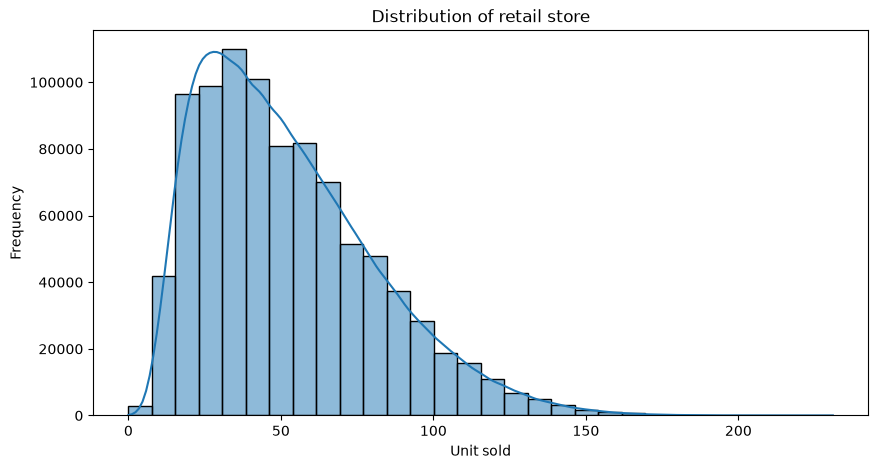

In [11]:
plt.figure(figsize=(10,5))

sns.histplot(
    data =df,
    x = 'sales',
    bins= 30,
    kde = True,
)

plt.title("Distribution of retail store")
plt.xlabel("Unit sold")
plt.ylabel("Frequency")

plt.show()

In [12]:
#total sales for each store
store_sales = df.groupby('store')['sales'].sum()

store_sales

store
1     4315603
2     6120128
3     5435144
4     5012639
5     3631016
6     3627670
7     3320009
8     5856169
9     5025976
10    5360158
Name: sales, dtype: int64

In [13]:
#storing by sales
store_sales = store_sales.sort_values(ascending = False)
store_sales

store
2     6120128
8     5856169
3     5435144
10    5360158
9     5025976
4     5012639
1     4315603
5     3631016
6     3627670
7     3320009
Name: sales, dtype: int64

Text(0, 0.5, 'Total Sales')

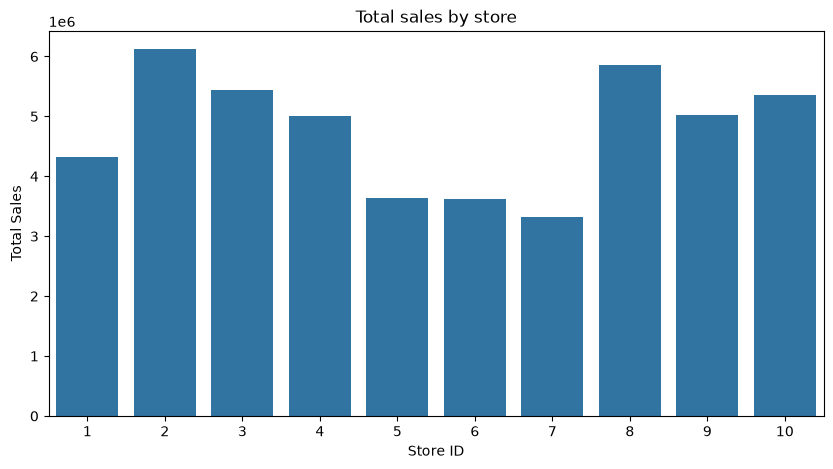

In [14]:
#visualize

plt.figure(figsize=(10,5))

sns.barplot(
    x = store_sales.index,
    y = store_sales.values,
)

plt.title("Total sales by store")
plt.xlabel("Store ID")
plt.ylabel("Total Sales")


In [15]:
#by performance basis 

best_store = store_sales.idxmax()

print("Best store---->",best_store)
print("Total sales--->",store_sales.max())

Best store----> 2
Total sales---> 6120128


In [16]:
#least performing 

lowest_store = store_sales.idxmin()

print("Lowest store---->", lowest_store)
print("Total sales----->",store_sales.min())

Lowest store----> 7
Total sales-----> 3320009


In [17]:
#Total sales for each product

product_sales = df.groupby('item')['sales'].sum()
product_sales

item
1      401384
2     1069564
3      669087
4      401907
5      335230
6     1068281
7     1068777
8     1405108
9      938379
10    1337133
11    1271925
12    1271534
13    1539621
14    1071531
15    1607442
16     468480
17     602486
18    1538876
19     736892
20     867641
21     736190
22    1469971
23     534979
24    1205975
25    1473334
26     869981
27     402628
28    1604713
29    1271240
30     736554
31    1070845
32     803107
33    1270183
34     469935
35    1201541
36    1406548
37     534258
38    1470330
39     801311
40     534094
41     401759
42     669925
43     936635
44     536811
45    1471467
46    1070764
47     401781
48     937703
49     535663
50    1203009
Name: sales, dtype: int64

In [18]:
#sorting product by sales

product_sales = product_sales.sort_values(ascending = False)
product_sales

item
15    1607442
28    1604713
13    1539621
18    1538876
25    1473334
45    1471467
38    1470330
22    1469971
36    1406548
8     1405108
10    1337133
11    1271925
12    1271534
29    1271240
33    1270183
24    1205975
50    1203009
35    1201541
14    1071531
31    1070845
46    1070764
2     1069564
7     1068777
6     1068281
9      938379
48     937703
43     936635
26     869981
20     867641
32     803107
39     801311
19     736892
30     736554
21     736190
42     669925
3      669087
17     602486
44     536811
49     535663
23     534979
37     534258
40     534094
34     469935
16     468480
27     402628
4      401907
47     401781
41     401759
1      401384
5      335230
Name: sales, dtype: int64

In [19]:
#Top selling product

top_10_product = product_sales.head(10)

top_10_product

item
15    1607442
28    1604713
13    1539621
18    1538876
25    1473334
45    1471467
38    1470330
22    1469971
36    1406548
8     1405108
Name: sales, dtype: int64

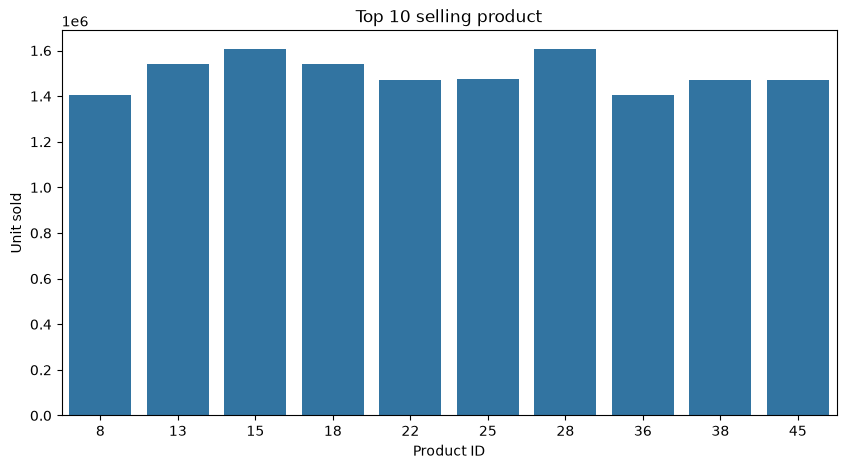

In [20]:
plt.figure(figsize=(10,5))

sns.barplot(
    x =top_10_product.index,
    y =top_10_product.values
)

plt.title("Top 10 selling product")
plt.xlabel("Product ID")
plt.ylabel("Unit sold")

plt.show()

In [21]:
#lowest selling product 

lowest_10_products = product_sales.tail(10)

lowest_10_products

item
37    534258
40    534094
34    469935
16    468480
27    402628
4     401907
47    401781
41    401759
1     401384
5     335230
Name: sales, dtype: int64

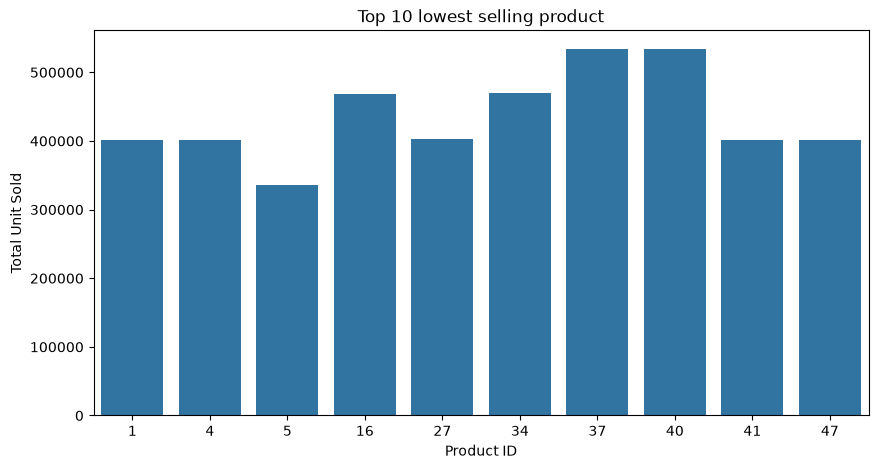

In [22]:
plt.figure(figsize=(10,5))

sns.barplot(
    x = lowest_10_products.index,
    y = lowest_10_products.values
)

plt.title("Top 10 lowest selling product")
plt.xlabel("Product ID")
plt.ylabel("Total Unit Sold")

plt.show()


In [23]:
df['month'] = df['date'].dt.month
df[['date', 'month']].head()
    

,date,month
0,2013-01-01,1
1,2013-01-02,1
2,2013-01-03,1
3,2013-01-04,1
4,2013-01-05,1


In [24]:
monthly_sales = df.groupby(
    df['date'].dt.to_period('M')
)['sales'].sum()

monthly_sales

date
2013-01     454904
2013-02     459417
2013-03     617382
2013-04     682274
2013-05     763242
2013-06     795597
2013-07     855922
2013-08     766761
2013-09     689907
2013-10     656587
2013-11     692643
2013-12     506607
2014-01     525987
2014-02     529117
2014-03     704301
2014-04     788914
2014-05     882877
2014-06     906842
2014-07     989010
2014-08     885596
2014-09     785124
2014-10     758883
2014-11     800783
2014-12     578048
2015-01     552513
2015-02     551317
2015-03     730951
2015-04     824467
2015-05     926902
2015-06     937184
2015-07    1037350
2015-08     920401
2015-09     823332
2015-10     797253
2015-11     827645
2015-12     607572
2016-01     602439
2016-02     614957
2016-03     790881
2016-04     901950
2016-05     988730
2016-06    1022664
2016-07    1138718
2016-08     981494
2016-09     896831
2016-10     863637
2016-11     891448
2016-12     663411
2017-01     617306
2017-02     621369
2017-03     822667
2017-04     938862
2017-05

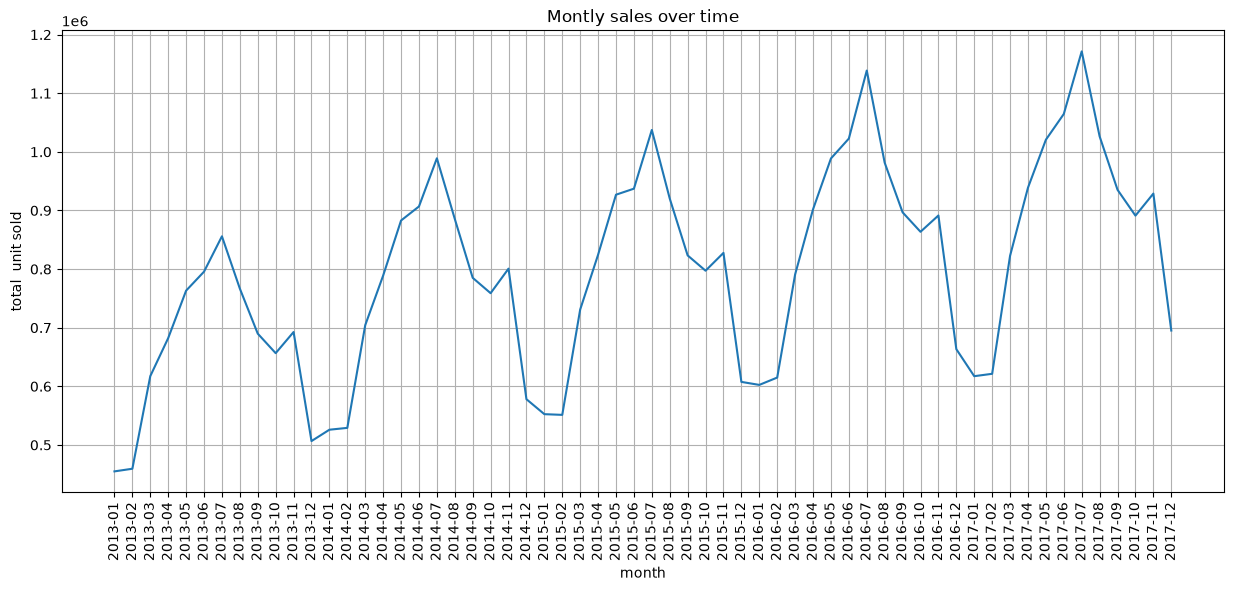

In [27]:
plt.figure(figsize=(15,6))

plt.plot(
    monthly_sales.index.astype(str),
    monthly_sales.values
)

plt.title("Montly sales over time")
plt.xlabel("month")
plt.ylabel("total  unit sold")

plt.xticks(rotation = 90)
plt.grid(True)

plt.show()

In [30]:
print("Hightest Sales month---->",monthly_sales.idxmax())
print("Highest monthly sales--->",monthly_sales.max())

print("Lowest sales month------>",monthly_sales.idxmin())
print("Lowest montlhy sales---->",monthly_sales.min())

Hightest Sales month----> 2017-07
Highest monthly sales---> 1171393
Lowest sales month------> 2013-01
Lowest montlhy sales----> 454904


In [32]:
average_monthly_sales = df.groupby(
    df['date'].dt.month
)['sales'].mean()

average_monthly_sales

date
1     35.524503
2     39.378397
3     47.305574
4     55.152893
5     59.128219
6     63.025480
7     66.998619
8     59.105226
9     55.072760
10    51.193806
11    55.218080
12    39.365265
Name: sales, dtype: float64

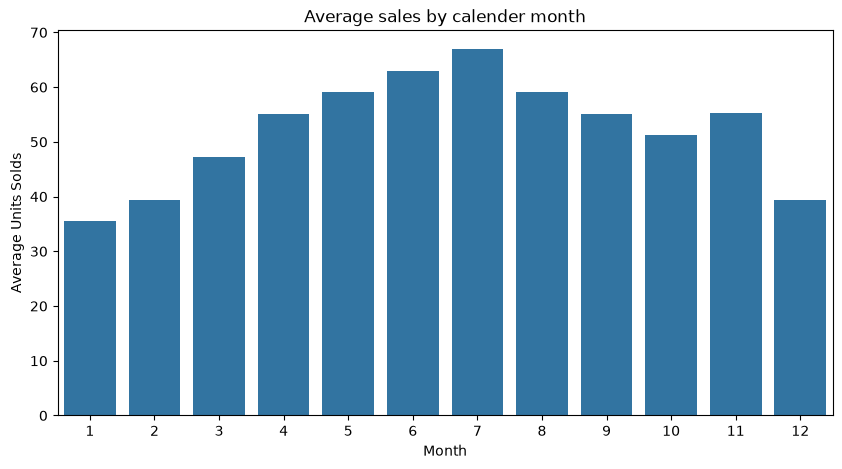

In [35]:
plt.figure(figsize=(10,5))

sns.barplot(
    x = average_monthly_sales.index,
    y = average_monthly_sales.values
)

plt.title("Average sales by calender month")
plt.xlabel("Month")
plt.ylabel("Average Units Solds")

plt.show()


In [36]:
df['year'] = df['date'].dt.year
df[['date', 'year']].head()

,date,year
0,2013-01-01,2013
1,2013-01-02,2013
2,2013-01-03,2013
3,2013-01-04,2013
4,2013-01-05,2013


In [38]:
yearly_sales = df.groupby('year')['sales'].sum()

yearly_sales

year
2013     7941243
2014     9135482
2015     9536887
2016    10357160
2017    10733740
Name: sales, dtype: int64

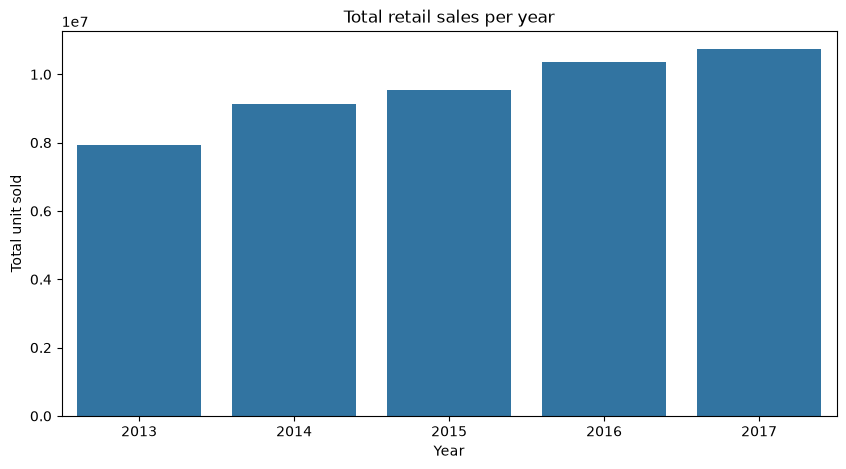

In [39]:
plt.figure(figsize=(10,5))

sns.barplot(
    x = yearly_sales.index,
    y = yearly_sales.values
)

plt.title("Total retail sales per year")
plt.xlabel("Year")
plt.ylabel("Total unit sold")

plt.show()

In [41]:
yearly_growth = yearly_sales.pct_change() * 100 

yearly_growth

year
2013          NaN
2014    15.038439
2015     4.393912
2016     8.601056
2017     3.635939
Name: sales, dtype: float64

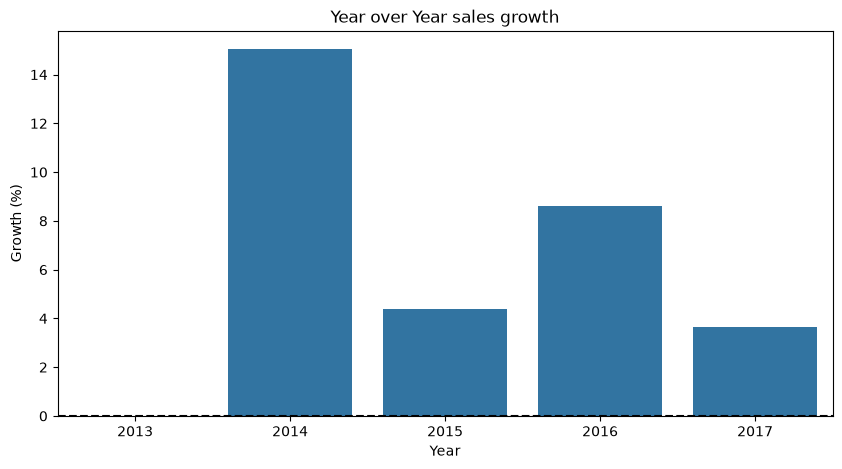

In [43]:
plt.figure(figsize=(10,5))

sns.barplot(
    x = yearly_growth.index,
    y = yearly_growth.values
)

plt.axhline(y=0 , color = 'black',linestyle='--')

plt.title("Year over Year sales growth")
plt.xlabel("Year")
plt.ylabel("Growth (%)")

plt.show()

In [45]:
df.isnull().sum()

date     0
store    0
item     0
sales    0
month    0
year     0
dtype: int64

In [46]:
missing_percentage = (df.isnull().sum() / len(df))*100

print(missing_percentage)


date     0.0
store    0.0
item     0.0
sales    0.0
month    0.0
year     0.0
dtype: float64


In [48]:
print("Total Duplicated rows:", df.duplicated().sum())

Total Duplicated rows: 0


In [49]:
date_range = pd.date_range(
    start=df['date'].min(),
    end=df['date'].max(),
    freq='D'
)

missing_dates = date_range.difference(df['date'].unique())

print("Total Missing Dates:", len(missing_dates))
print("Missing Dates:", missing_dates)

Total Missing Dates: 0
Missing Dates: DatetimeIndex([], dtype='datetime64[ns]', freq='D')


In [50]:
print("Unique Stores:", sorted(df['store'].unique()))
print("Unique Items:", sorted(df['item'].unique()))

print("Negative Sales:", (df['sales'] < 0).sum())
print("Zero Sales:", (df['sales'] == 0).sum())

Unique Stores: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10)]
Unique Items: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23), np.int64(24), np.int64(25), np.int64(26), np.int64(27), np.int64(28), np.int64(29), np.int64(30), np.int64(31), np.int64(32), np.int64(33), np.int64(34), np.int64(35), np.int64(36), np.int64(37), np.int64(38), np.int64(39), np.int64(40), np.int64(41), np.int64(42), np.int64(43), np.int64(44), np.int64(45), np.int64(46), np.int64(47), np.int64(48), np.int64(49), np.int64(50)]
Negative Sales: 0
Zero Sales: 1
